# Task 2 — Proximal Policy Optimization (PPO)

A **thin driver** around the Task 2 scripts (same pattern as Task 1): every experiment is a plain command listed in
the README (`python -m task2_ppo.continue_train …`, `python -m task2_ppo.evaluate …`, …). The notebook launches them,
shows live training curves from the saved per-update logs, and draws the report figures from `results/task2_ppo/`.
Finished steps are skipped; set `FORCE = True` to redo them. The stop button kills the running script.

| Step | What it runs | Rough time (RTX 5060 laptop, estimate) |
|---|---|---|
| 0 | objective unit tests | seconds |
| 1 | standard PPO continuation: 20 updates from the supplied midpoint | 15–25 min |
| 2 | held-out evaluation of the midpoint and the standard run | ~6–8 min each |
| 3 | clipping study: cached-batch geometry + 3 matched 8-update forks (ε = 0.05, 0.2, 0.5) + evaluation | ~45–60 min |
| 4 | KL study: 2 more forks (β_KL = 0, 0.2; the β_KL = 0.1 fork is shared with step 3) + evaluation | ~30 min |
| 5–6 | tables, report figures (`report/figures/`), qualitative candidates | seconds |

Keep the laptop plugged in and in Performance mode: this task reports wall-clock time and peak VRAM.

In [1]:
# --- setup ---------------------------------------------------------------------------------------
import os, sys, json
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "configs").exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
import torch
from IPython.display import display, Markdown
from common.data import load_yaml, repo_path
from common.live import run_live
from task2_ppo import plots

CONFIG = os.environ.get("PA2_PPO_CONFIG", "configs/ppo.yaml")
FORCE = False
cfg = load_yaml(CONFIG)
RES = repo_path(cfg["results_dir"])
MIDPOINT = cfg["paths"]["ppo_midpoint_policy"]

def done(path):
    return (not FORCE) and repo_path(path).exists()

print("repo root :", ROOT)
print("python    :", sys.executable)
if ".venv" not in sys.executable:
    print("WARNING: this kernel is not the repo's .venv Python - select the .venv kernel before running.")
print("torch     :", torch.__version__, "| CUDA:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU")
print("config    :", CONFIG, "| updates", cfg["updates"], "| fork updates", cfg["fork_updates"],
      "| eps", cfg["clip_epsilon"], "| beta_KL", cfg["kl_beta"], "| clip values", cfg["clip_values"], "| KL values", cfg["kl_values"])
pd.set_option("display.max_colwidth", 120)

d:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


repo root : D:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining
python    : d:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining\.venv\Scripts\python.exe
torch     : 2.11.0+cu128 | CUDA: True | NVIDIA GeForce RTX 5060 Laptop GPU
config    : configs/ppo.yaml | updates 20 | fork updates 8 | eps 0.2 | beta_KL 0.1 | clip values [0.05, 0.2, 0.5] | KL values [0.0, 0.1, 0.2]


## Step 0 — objective validation
Includes the corrected clipped surrogate (pessimistic `min`), a brute-force GAE check and the KL reward-shaping check.

In [2]:
run_live("scripts.test_objectives", title="Objective unit tests", refresh_s=1)

Objective unit tests
FINISHED OK  |  elapsed 0m02s  |  full log: D:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining\results\notebook_logs\scripts_test_objectives.log

PASS  test_dpo_at_initialisation_is_log2
PASS  test_dpo_matches_manual_formula
PASS  test_dpo_gradient_direction
PASS  test_ppo_clip_positive_advantage
PASS  test_ppo_clip_negative_advantage
PASS  test_ppo_inside_trust_region_is_unclipped
PASS  test_ppo_mask_ignores_padding
PASS  test_gae_matches_brute_force
PASS  test_shaped_rewards_kl_and_terminal
PASS  test_gae_terminal_reward
PASS  test_grpo_advantages_are_per_group
PASS  test_grpo_advantages_invariant_to_other_groups
PASS  test_grpo_loss_normalisations
13/13 passed


## Step 1 — standard PPO continuation (20 updates)

Continues the supplied midpoint policy LoRA **and** critic. Each update: sample one response per prompt (rollout cap
512 tokens), score it with the learned reward model (−1 if the cap is hit without EOS), KL-shape the token rewards
against the frozen reference, compute GAE advantages/returns with the critic, then two clipped-surrogate epochs for
the policy and two MSE epochs for the critic. Dropout is disabled so the importance ratio is exactly 1 in the first
epoch of every update. Every update is logged to `results/task2_ppo/standard/train_log.jsonl`.

Standard PPO adapter exists - skipping (set FORCE = True to retrain).


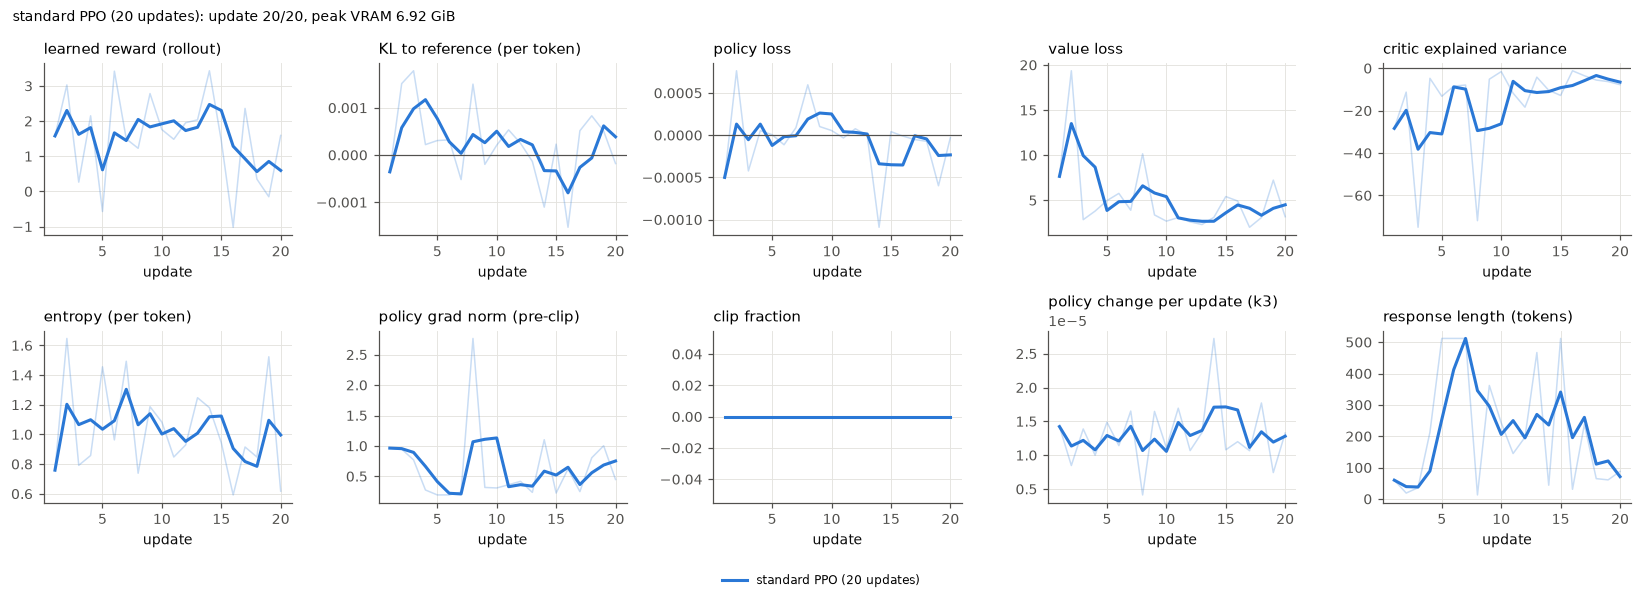

**Standard continuation:** wall-clock **3.0 min**, peak VRAM **6.921 GiB**, 4330 generated tokens

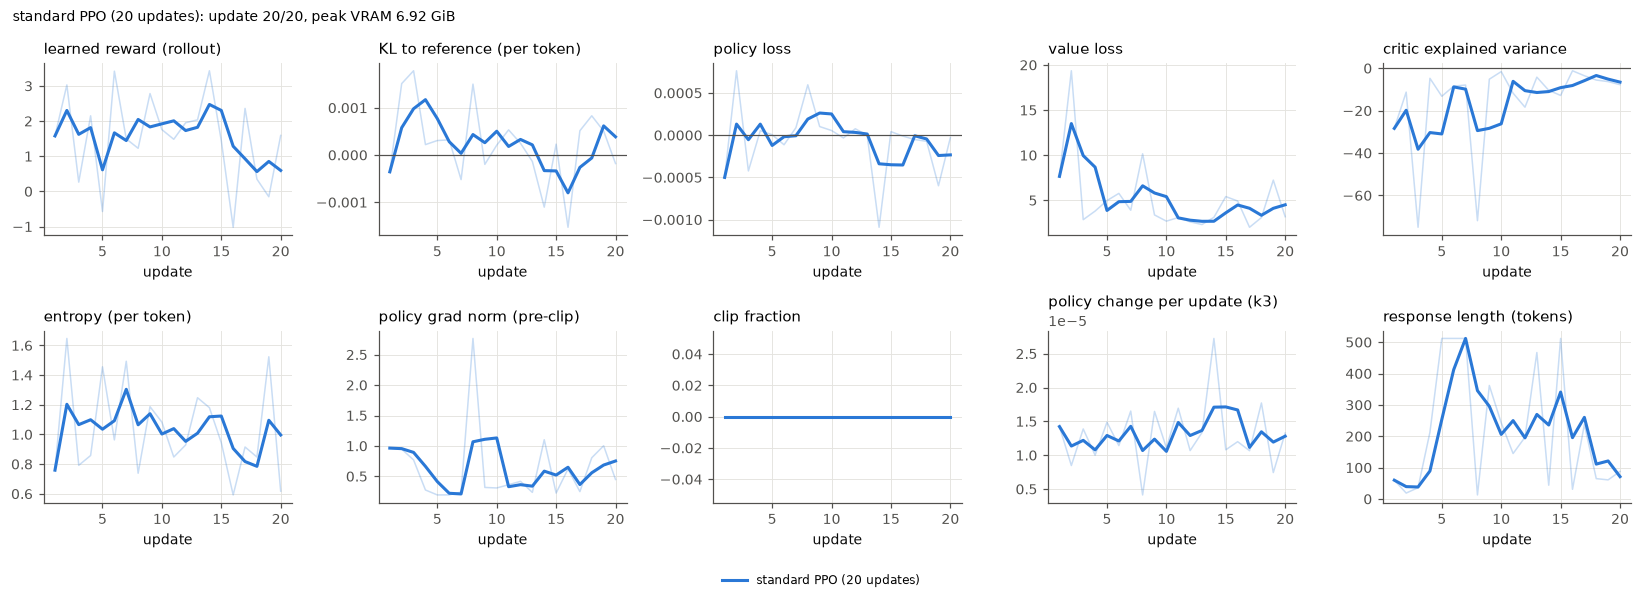

In [3]:
if done("outputs/task2_ppo/standard/adapter_model.safetensors"):
    print("Standard PPO adapter exists - skipping (set FORCE = True to retrain).")
    display(plots.train_curves(cfg, ["standard"]))
else:
    run_live("task2_ppo.continue_train", "--config", CONFIG, "--run-name", "standard",
             title="Standard PPO continuation (20 updates)", plot_fn=lambda: plots.train_curves(cfg, ["standard"]))
summary = plots._json(RES / "standard" / "train_summary.json")
display(Markdown(f"**Standard continuation:** wall-clock **{summary['wall_clock_s'] / 60:.1f} min**, "
                 f"peak VRAM **{summary['peak_vram_gib']} GiB**, {summary['generated_tokens']} generated tokens"))

## Step 2 — held-out evaluation: supplied midpoint vs standard run

Common protocol (`common/rl_eval.py`): the first 96 held-out prompts that fit the prompt cap, one sampled response each
(fixed seed, same sampling settings), evaluation cap 768 tokens. Reported: learned reward (raw and with the missing-EOS
penalty, 95% bootstrap CI), sampled-token KL to the reference, entropy, length, truncation rate.

In [4]:
for name, adapter in [("midpoint", MIDPOINT), ("standard", "outputs/task2_ppo/standard")]:
    if done(f"{cfg['results_dir']}/{name}/eval_heldout.json"):
        print(f"{name}: evaluation exists - skipping.")
    else:
        run_live("task2_ppo.evaluate", "--config", CONFIG, "--adapter", adapter, "--name", name,
                 title=f"Held-out evaluation: {name}", refresh_s=10)

midpoint: evaluation exists - skipping.
standard: evaluation exists - skipping.


## Step 3 — clipping study

**Part A (cached batch).** The supplied 32 cached rollouts are rebuilt token-for-token and validated against the cache
(recomputed reference log-probs and critic values must match). For each ε the script reports the clip fraction
(tokens with ρ outside [1−ε, 1+ε]) and the affected fraction (tokens where the clip binds and the gradient is zeroed)
for the midpoint policy against the cached old log-probs, and again after two clipped-surrogate steps on that batch,
each ε starting from identical weights. **Part B (forks).** Three matched 8-update continuations from the midpoint
(same prompts, β_KL fixed), each evaluated with the common protocol.

Clipping study (cached batch + forks)
FINISHED OK  |  elapsed 2m56s  |  full log: D:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining\results\notebook_logs\task2_ppo_analyze_clipping.log



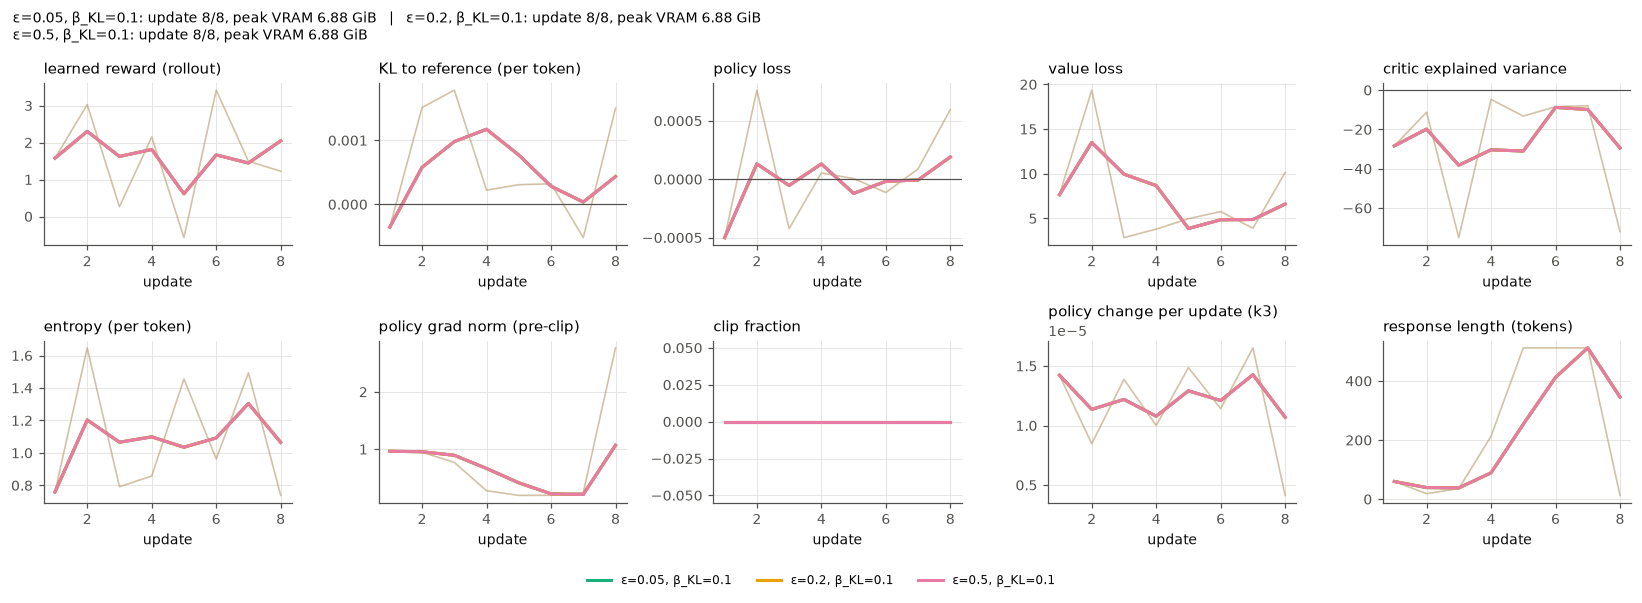

W1010 15:23:27.982000 24936 .venv\Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels
[clip] cached batch: 29 rollouts / 7494 response tokens used (0 skipped: re-tokenisation length mismatch or missing prompt; 3 dropped as misaligned)
[clip] validation: {'n_rollouts': 29, 'n_tokens': 7494, 'dropped_misaligned': [671, 175, 961], 'alignment_rule': 'drop a rollout if mean |ref diff| > 0.1 or max |ref diff| > 2.0', 'ref_logp_abs_diff_mean': 0.0165, 'ref_logp_abs_diff_max': 0.33744, 'midpoint_vs_cached_old_abs_diff_mean': 0.01612, 'midpoint_vs_cached_old_abs_diff_max': 0.37605, 'critic_value_abs_diff_mean': 0.04006, 'critic_value_abs_diff_max': 0.38672}
[clip] eps=0.05: midpoint clip=0.0991 affected=0.0488 | after 2 steps clip=0.0986 affected=0.0487 surrogate -0.0001 -> clipped -0.0013
[clip] eps=0.2: midpoint clip=0.0011 affected=0.0007 | after 2 steps clip=0.0011 affected=0.0007 surrogate -0.0001 -> clipped -0.0002
[clip] eps=

**Cached-batch validation** (the reconstruction must reproduce the cache):

n_rollouts                                                                                           29
n_tokens                                                                                           7494
alignment_rule                          drop a rollout if mean |ref diff| > 0.1 or max |ref diff| > 2.0
ref_logp_abs_diff_mean                                                                         0.016504
ref_logp_abs_diff_max                                                                          0.337444
midpoint_vs_cached_old_abs_diff_mean                                                           0.016124
midpoint_vs_cached_old_abs_diff_max                                                            0.376048
critic_value_abs_diff_mean                                                                     0.040055
critic_value_abs_diff_max                                                                      0.386719
dtype: object

In [5]:
run_live("task2_ppo.analyze_clipping", "--config", CONFIG, title="Clipping study (cached batch + forks)",
         plot_fn=lambda: plots.train_curves(cfg, plots.CLIP_FORKS))
val = plots._json(RES / "clipping_cached.json")["validation"]
display(Markdown("**Cached-batch validation** (the reconstruction must reproduce the cache):"))
display(pd.Series({k: v for k, v in val.items() if k not in ("skipped", "dropped_misaligned")}))

## Step 4 — KL-pressure (reward over-optimisation) study

Matched 8-update forks with β_KL ∈ {0, 0.1, 0.2} at ε = 0.2 from the identical midpoint and prompts. The β_KL = 0.1 fork
is the same run as the ε = 0.2 fork of step 3 and is reused, not retrained.

KL-pressure study
FINISHED OK  |  elapsed 0m05s  |  full log: D:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining\results\notebook_logs\task2_ppo_ablate_kl.log



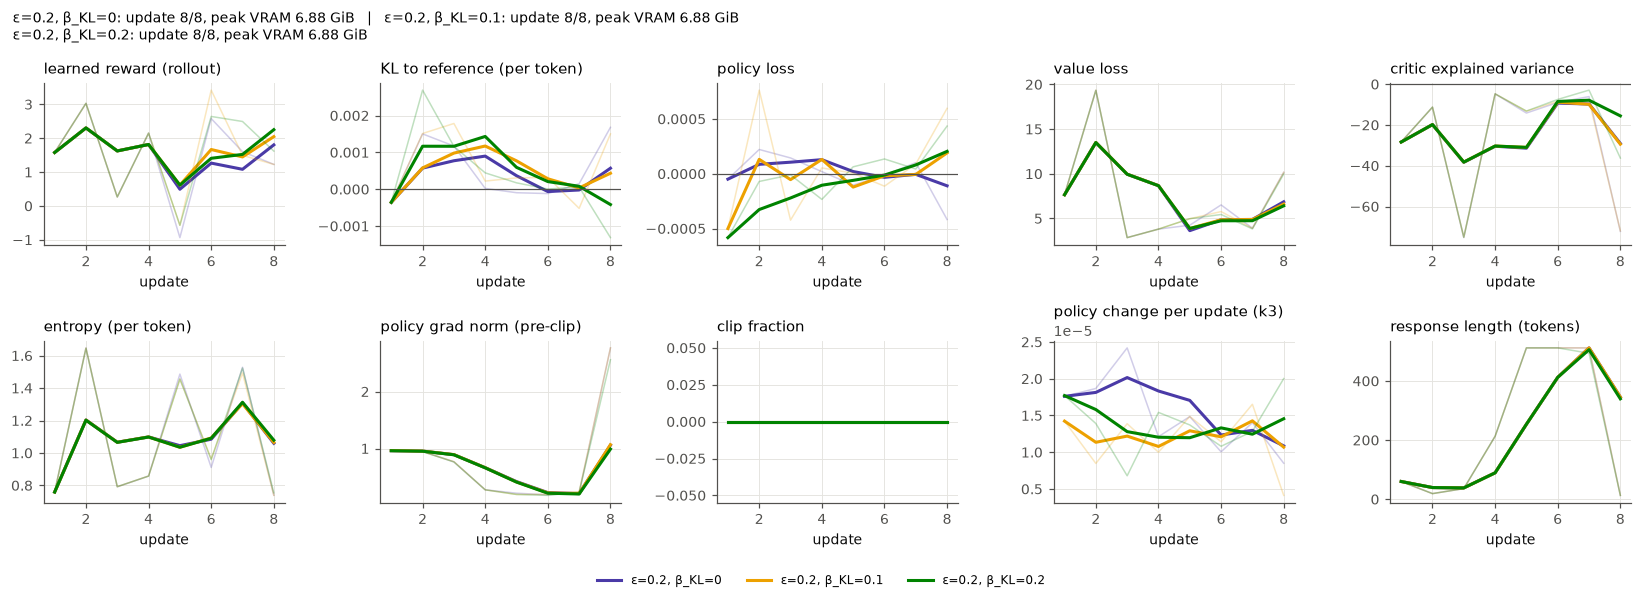

KL beta conditions: [0.0, 0.1, 0.2]
Fork update budget: 8
wrote D:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining\results\task2_ppo\summary_kl.csv


In [6]:
run_live("task2_ppo.ablate_kl", "--config", CONFIG, title="KL-pressure study",
         plot_fn=lambda: plots.train_curves(cfg, plots.KL_FORKS))

## Step 5 — results
Tables are recomputed from the saved JSON files; figures are saved to `report/figures/`.

In [7]:
import subprocess
for module in ("task2_ppo.analyze_clipping", "task2_ppo.ablate_kl"):
    subprocess.run([sys.executable, "-m", module, "--config", CONFIG, "--summary-only"], cwd=ROOT, check=False,
                   stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)

rows = []
for name in ["midpoint", "standard", *plots.CLIP_FORKS, *[k for k in plots.KL_FORKS if k not in plots.CLIP_FORKS]]:
    ev = plots._json(RES / name / "eval_heldout.json")
    if ev:
        rows.append({"condition": name, "reward_raw": ev["reward_raw_mean"], "reward_ci95": ev["reward_raw_ci95"],
                     "reward_eos_penalised": ev["reward_mean"], "kl_token": ev["kl_token_mean"], "kl_seq": ev["kl_seq_mean"],
                     "entropy": ev["entropy_mean"], "len_mean": ev["response_tokens"]["mean"],
                     "len_std": ev["response_tokens"]["std"], "truncation": ev["truncation_rate"]})
display(Markdown("**Held-out evaluation (common protocol)**"))
display(pd.DataFrame(rows).set_index("condition").round(4))
for f, title in [("summary_clipping.csv", "Clipping study"), ("summary_kl.csv", "KL-pressure study")]:
    if (RES / f).exists():
        display(Markdown(f"**{title}**"))
        display(pd.read_csv(RES / f).set_index(pd.read_csv(RES / f).columns[0]).T)

**Held-out evaluation (common protocol)**

,reward_raw,reward_ci95,reward_eos_penalised,kl_token,kl_seq,entropy,len_mean,len_std,truncation
condition,,,,,,,,,
midpoint,1.8226,"[1.5651304880777994, 2.042091719309489]",1.7288,-0.0,-0.0074,0.9402,297.1458,259.5459,0.0938
standard,1.7425,"[1.4631256739298502, 1.986185630162557]",1.6175,0.0,0.0027,0.9440,298.8021,264.0595,0.1250
eps0.05_kl0.1,1.8443,"[1.5710373719533284, 2.085315132141113]",1.7505,-0.0,-0.0001,0.9485,296.2396,261.3255,0.0938
eps0.2_kl0.1,1.8443,"[1.5710373719533284, 2.085315132141113]",1.7505,-0.0,-0.0001,0.9485,296.2396,261.3255,0.0938
eps0.5_kl0.1,1.8443,"[1.5710373719533284, 2.085315132141113]",1.7505,-0.0,-0.0001,0.9485,296.2396,261.3255,0.0938
eps0.2_kl0,1.8675,"[1.573029104868571, 2.133275063832601]",1.8050,0.0,0.0045,0.9394,290.5729,254.2236,0.0625
eps0.2_kl0.2,1.7977,"[1.5051850001017253, 2.0627050399780273]",1.6727,-0.0,-0.0041,0.9443,305.6667,267.9067,0.1250


**Clipping study**

epsilon,0.05,0.20,0.50
fork,eps0.05_kl0.1,eps0.2_kl0.1,eps0.5_kl0.1
cached_clip_fraction_midpoint,0.099146,0.001068,0.0
cached_noise_floor_clip_fraction,0.102749,0.001068,0.0
cached_affected_fraction_midpoint,0.048839,0.000667,0.0
cached_clip_fraction_after_steps,0.098612,0.001068,0.0
cached_affected_fraction_after_steps,0.048706,0.000667,0.0
cached_surrogate_clipped_after_steps,-0.001304,-0.000218,-0.000075
cached_kl_k3_after_steps,0.000462,0.000458,0.000462
train_updates,8,8,8
train_generated_tokens,1877,1877,1877


**KL-pressure study**

condition,midpoint (start),standard (20 updates),eps0.2_kl0,eps0.2_kl0.1,eps0.2_kl0.2
kl_beta,NaN,0.100000,0.000000,1.000000e-01,0.200000
heldout_reward_raw,1.822592,1.742511,1.867452,1.844262e+00,1.797694
heldout_reward_raw_ci_lo,1.565130,1.463126,1.573029,1.571037e+00,1.505185
heldout_reward_raw_ci_hi,2.042092,1.986186,2.133275,2.085315e+00,2.062705
heldout_reward_eos_penalised,1.728842,1.617511,1.804952,1.750512e+00,1.672694
heldout_kl_token,-0.000025,0.000009,0.000016,-3.184454e-07,-0.000013
heldout_kl_seq,-0.007385,0.002663,0.004541,-9.433613e-05,-0.004078
heldout_entropy,0.940221,0.944046,0.939426,9.484883e-01,0.944305
heldout_len_mean,297.145833,298.802083,290.572917,2.962396e+02,305.666667
heldout_len_std,259.545917,264.059519,254.223603,2.613255e+02,267.906726


saved D:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining\report\figures\task2_standard_training.png


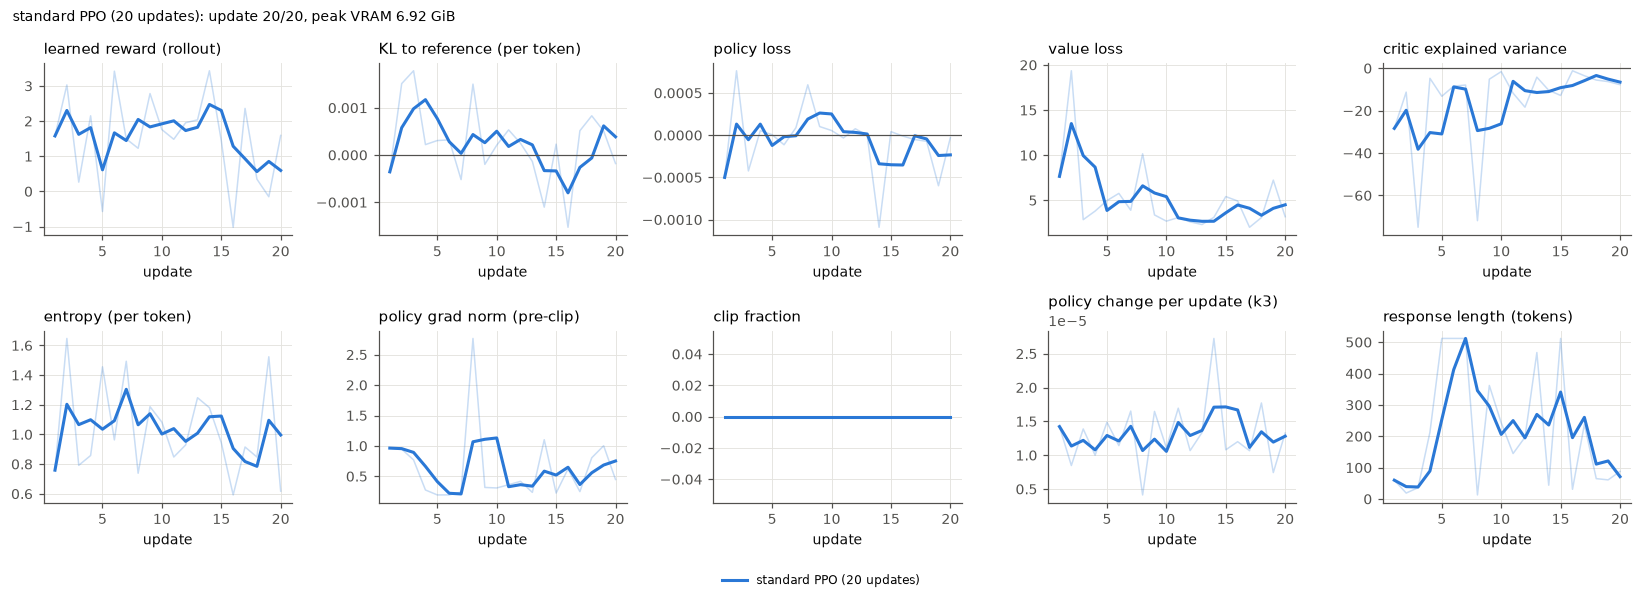

saved D:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining\report\figures\task2_clipping_study.png


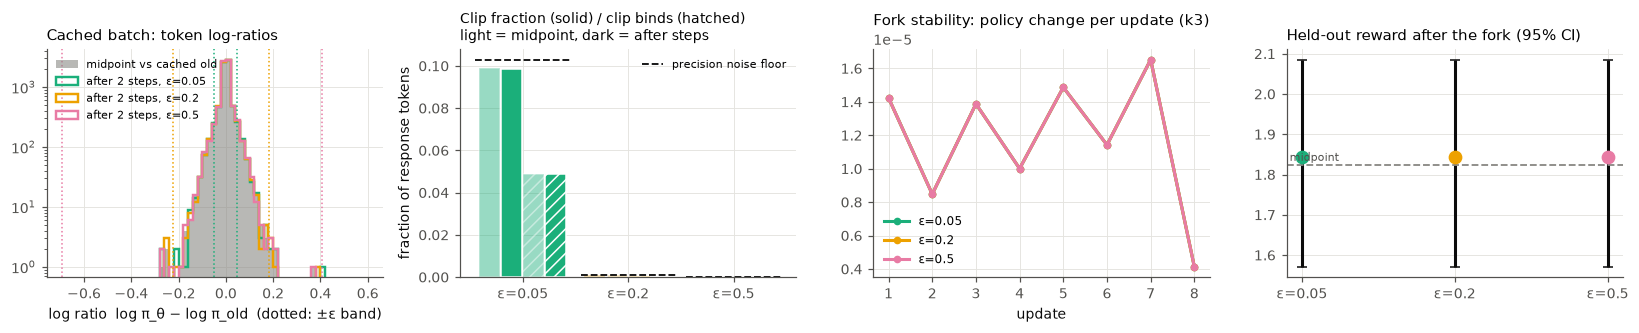

saved D:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining\report\figures\task2_kl_study.png


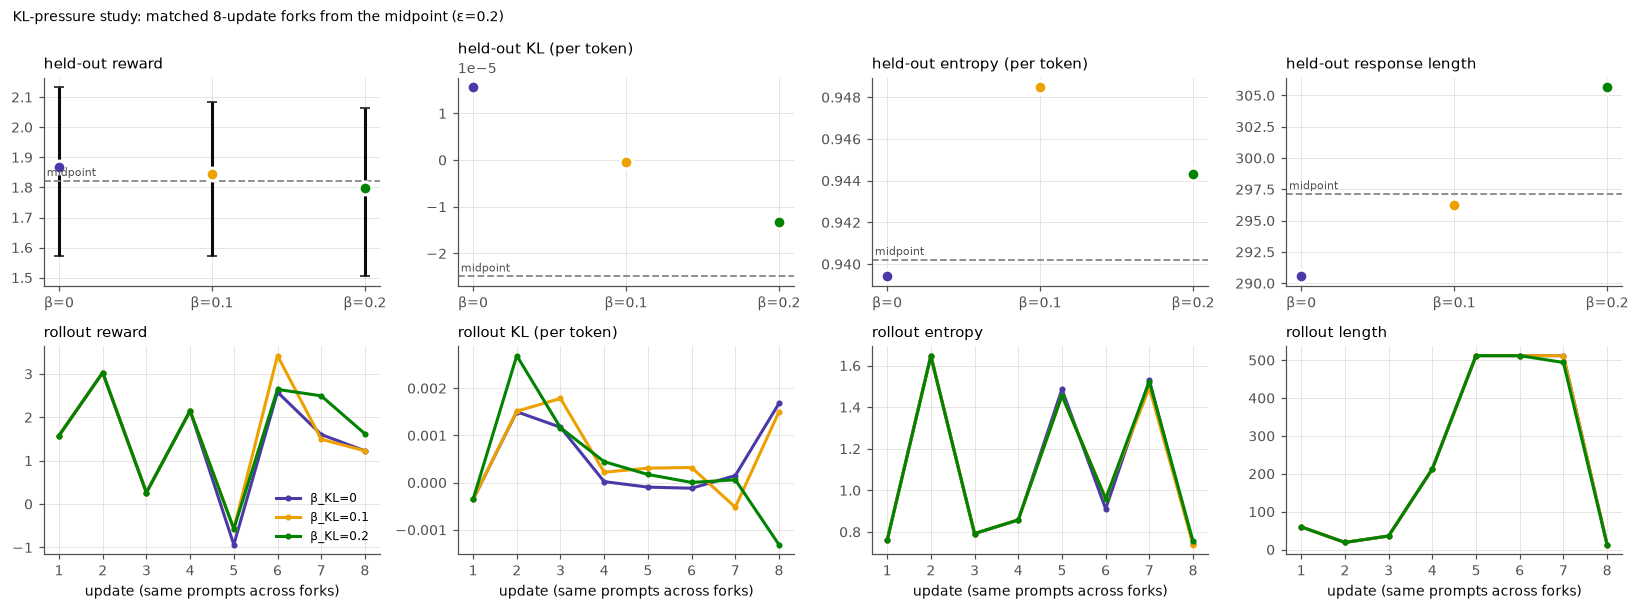

saved D:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining\report\figures\task2_fork_training.png


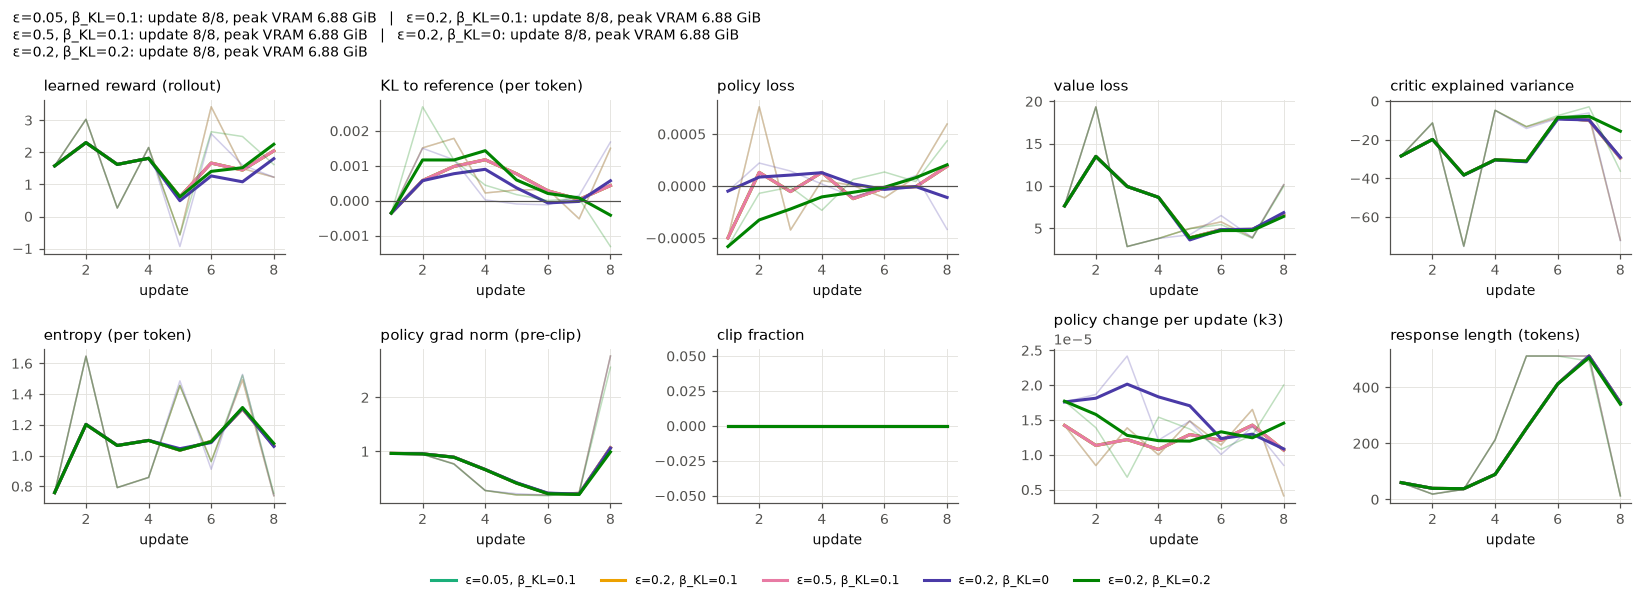

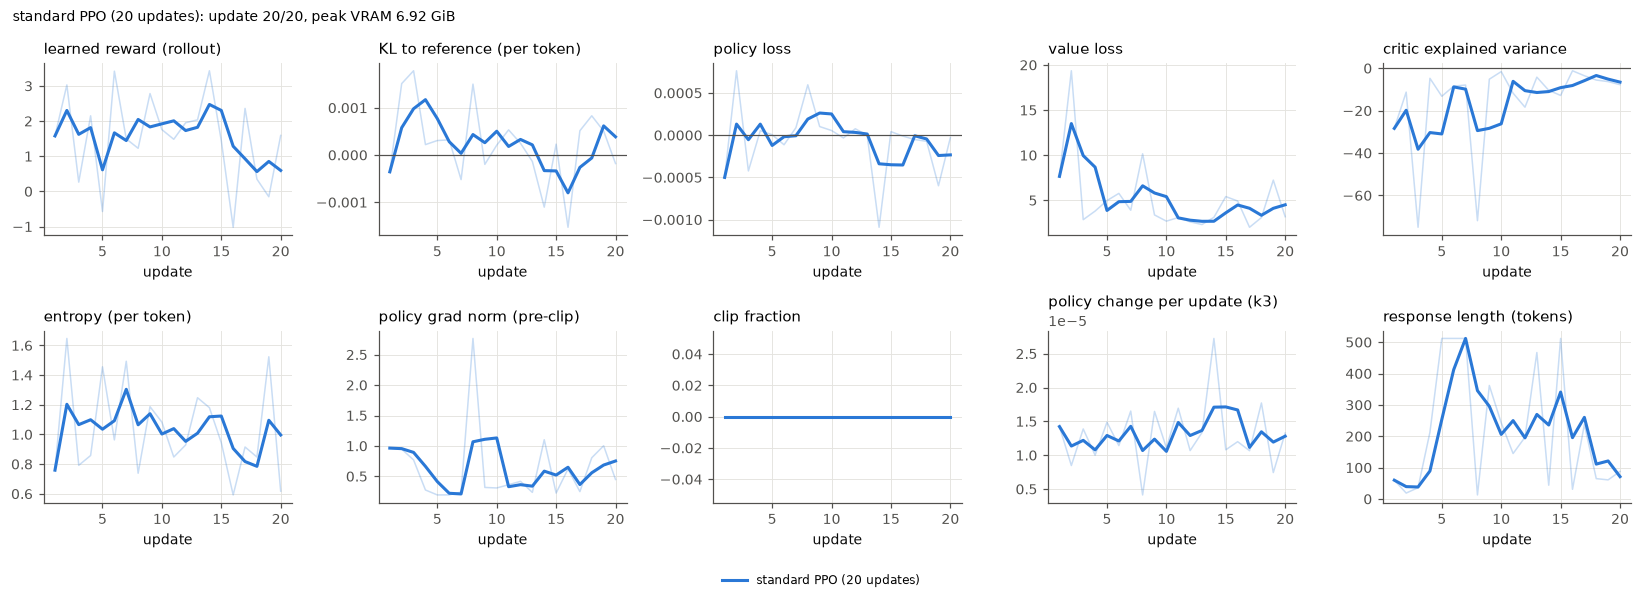

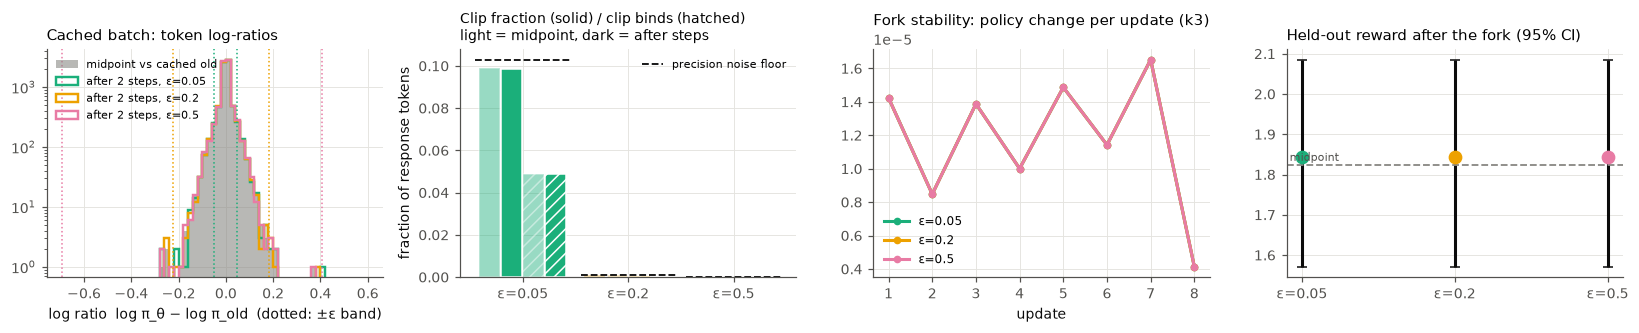

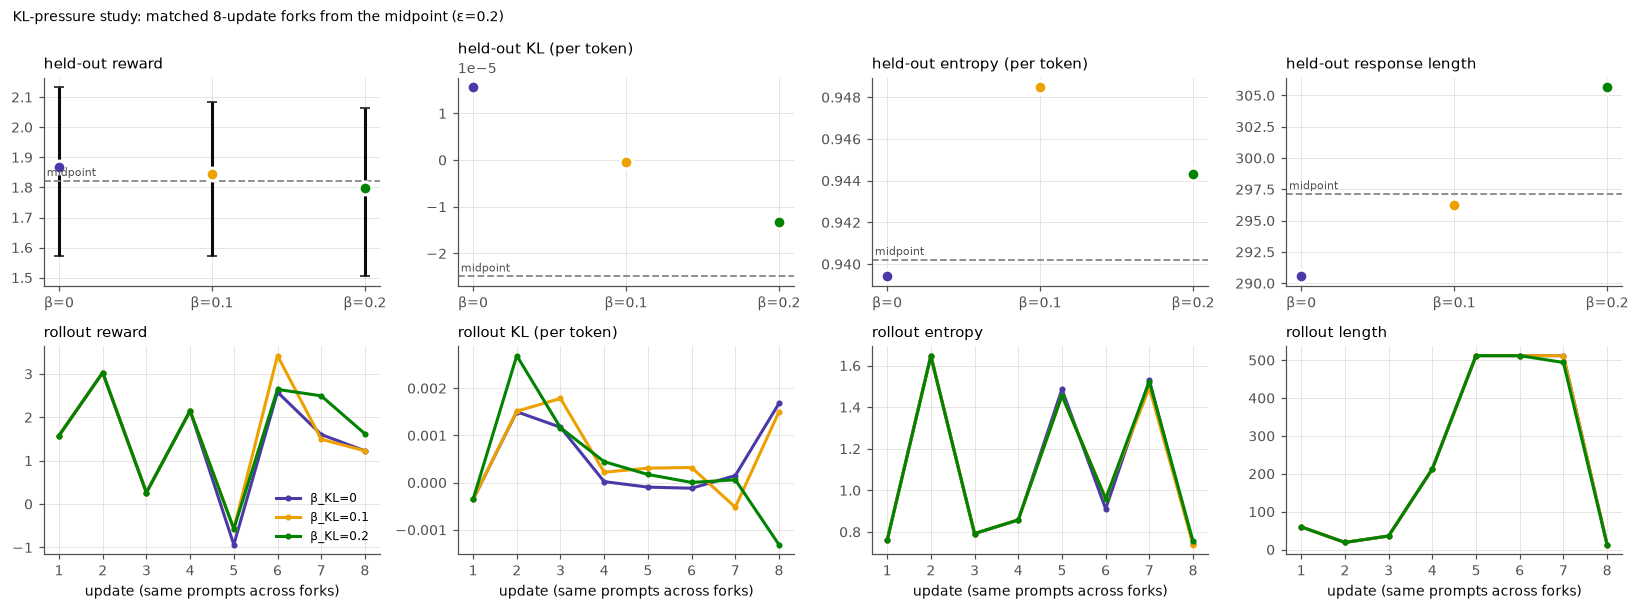

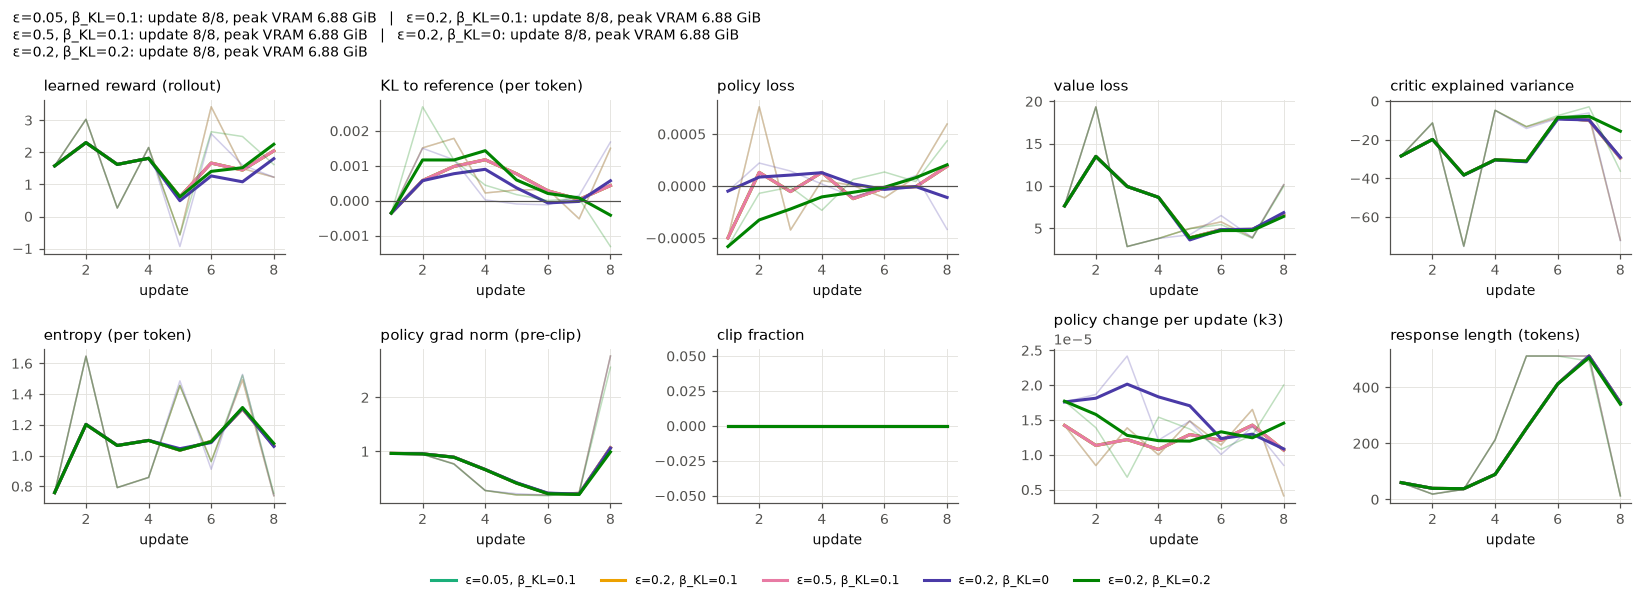

In [8]:
figs = {
    "task2_standard_training": plots.train_curves(cfg, ["standard"]),
    "task2_clipping_study": plots.clipping_study(cfg),
    "task2_kl_study": plots.kl_study(cfg),
    "task2_fork_training": plots.train_curves(cfg, plots.CLIP_FORKS + ["eps0.2_kl0", "eps0.2_kl0.2"]),
}
for name, fig in figs.items():
    plots.save(fig, name)
    if fig is not None:
        display(fig)

## Step 6 — qualitative candidates

The report needs at least one held-out case where reward and response quality move together and one where they
disagree. These tables only **rank candidates** by reward change on the same prompt; read the responses and judge
quality yourself before quoting anything.

In [9]:
display(Markdown("**Largest reward gains: standard PPO vs midpoint** (agreement or reward hacking?)"))
display(plots.reward_change_candidates(cfg, "standard", "midpoint", k=6))
display(Markdown("**Largest reward drops: standard PPO vs midpoint**"))
display(plots.reward_change_candidates(cfg, "standard", "midpoint", k=6, ascending=True))

**Largest reward gains: standard PPO vs midpoint** (agreement or reward hacking?)

,prompt_id,reward_change,standard_reward,midpoint_reward,standard_tokens,midpoint_tokens,standard_truncated,prompt,standard_response,midpoint_response
38,8c275b2f773ec083b990f252af74e39652ceaa13d482cf6f7a78e0f0354271a2,1.131836,2.740234,1.608398,580,768,False,Please provide a comprehensive research proposal that includes a hypothesis for conducting experiments related to co...,Research Proposal: Exploring the Impact of Social Media Influencers on Consumer Behavior Hypothesis: The presence of...,Research Proposal: Exploring the Impact of Social Media Influencers on Consumer Behavior Hypothesis: The presence of...
47,deea28c01e3cb09aceb216be5d2d1245384925634d73b6532a8e8ca2572946b5,0.925781,2.308594,1.382812,522,561,False,Can you write a Python code that generates a random sentence with a missing word for a language learning app? The ap...,Certainly! To create a Python script that generates a random sentence with a missing word for a language learning ap...,Certainly! To create a Python script that generates a random sentence with a missing word for a language learning ap...
57,6fa7bd820f04e821c0f7e6914f316d55acae44398fa8641d584c2e2fe262581a,0.662109,4.007812,3.345703,708,607,False,"Hi, can you make a one programming task for me? I need a PHP custom function ""smart\_sort\_array"", which accepts arg...",Certainly! Below is a PHP code snippet that implements the `smart_sort_array` function according to your specificati...,Certainly! Below is a PHP code snippet that implements the `smart_sort_array` function according to your specificati...
43,549538cb4267fef6a57d9d5e7a26a5c7442e57aa33d9bc39d809035c8f9a4ae5,0.577637,1.171875,0.594238,768,768,True,Provide a comprehensive analysis of the historical and contemporary examples of groups that have faced discriminatio...,"Discrimination has been a pervasive issue throughout history across different societies, cultures, and contexts. It ...","Discrimination has been a pervasive issue throughout history across different societies, cultures, and contexts. It ..."
4,3c88d94112cad274e15a0ff45ef91eb8e04689a528caf50433331ad7f7409af8,0.554688,3.105469,2.550781,372,353,False,How to build a professional photography concept?,"To build a professional photography concept, you can follow these steps: 1. Define your goal: What do you want to ac...","To build a professional photography concept, you can follow these steps: 1. Define your goal: What do you want to ac..."
64,de9a80e769756c36c3bec31ccca84a180e2862f7dd06ef5e5a36fde7caceaa2a,0.505859,3.521484,3.015625,476,447,False,difference between Adobe Premier Pro and iMovie. which one is better? both has same features. kindly elaborate,Both Adobe Premiere Pro and iMovie are powerful video editing software programs that offer similar features in terms...,Both Adobe Premiere Pro and iMovie are powerful video editing software programs that offer similar features in terms...


**Largest reward drops: standard PPO vs midpoint**

,prompt_id,reward_change,standard_reward,midpoint_reward,standard_tokens,midpoint_tokens,standard_truncated,prompt,standard_response,midpoint_response
35,df363c927f8727d9ebc6f7214215191c62a1ff41796c6b22f9ff37fa991f9121,-1.950684,-0.244629,1.706055,768,574,True,I want to parse a struct in a go source file and want to generate a avro schema from it. Please write a Go program t...,"To achieve this task, you can use the `golang.org/x/tools/imports` package for importing the necessary packages and ...","To achieve this task, you can use the `golang.org/x/tools/imports` package for importing the necessary packages and ..."
37,89329ac82483a5d974f7b853e22923e5405ffc6d81bab3c84a8beab932d48a71,-1.671875,0.751953,2.423828,89,176,False,"In this task, you will be presented with a question having multiple possible answers in Dutch language. And you shou...",The correct answer is A: gevonden. Explanation: This sentence describes someone who borrowed a metal detector to try...,The correct answer is: A gevonden Explanation: This sentence describes someone who borrowed a metal detector to try ...
33,a02b9f1af9a2009a5754fee7f82277e016c787814b8a5f8641864085ccceb4f9,-1.537109,0.664062,2.201172,426,600,False,Write a descriptive narrative about a protagonist who unexpectedly gains the power of flight and must quickly learn ...,"Once upon a time, there was a young woman named Ava. She had always been an ordinary person, with no special abiliti...","In the heart of a bustling metropolis lies an organization known as ""The Syndicate."" This shadowy group has been orc..."
56,15837ad2725266a35255f91d2e023ea644ede5cb9d7ec9270ab3c6dd6449a74c,-1.495605,0.137207,1.632812,768,610,True,"need to use Python to maximize a window and wait for a specific text , after the text appear , i need to write some ...","To achieve your goal using Python, you can utilize several libraries such as `selenium` for interacting with web pag...","To achieve your goal using Python, you can utilize several libraries such as `selenium` for interacting with web pag..."
1,a68322e9ef99336c810c507061658df3f91069069e937f4c2e840fbcfe55ba65,-1.141602,1.100586,2.242188,768,684,True,How can I use PHP to create a dynamic webpage that changes the appearance of the sun based on the time of day? For e...,"To achieve this effect in a dynamic web page with PHP and CSS, we'll need to do some server-side processing to deter...","To achieve this effect in a dynamic web page with PHP and CSS, we'll need to do some server-side processing to deter..."
71,481629a712a1e7f0d589280f76f945dc501b373fa433b6b5798a78f86231dab2,-1.067383,1.700195,2.767578,768,744,True,Create a twitter thread about Time Management. Create at least 30 tips. Create 30 unconventional novel time manageme...,"Here's my Twitter thread on time management: **Tip 1:** ""Start your day early to avoid the morning rush."" 🕒 **Tip 2:...","Here's my Twitter thread on time management: **Tip 1:** ""Start your day early to avoid the morning rush."" 🕒 **Tip 2:..."


In [10]:
display(Markdown("**β_KL = 0 fork vs midpoint: largest reward gains** (does reward rise without better answers when KL pressure is removed?)"))
display(plots.reward_change_candidates(cfg, "eps0.2_kl0", "midpoint", k=6))
display(Markdown("**High-reward responses that hit the length cap without EOS (β_KL = 0 fork)**"))
display(plots.high_reward_truncated(cfg, "eps0.2_kl0", k=6))

**β_KL = 0 fork vs midpoint: largest reward gains** (does reward rise without better answers when KL pressure is removed?)

,prompt_id,reward_change,eps0.2_kl0_reward,midpoint_reward,eps0.2_kl0_tokens,midpoint_tokens,eps0.2_kl0_truncated,prompt,eps0.2_kl0_response,midpoint_response
85,bdfcf969f2a84458b2498e0acc198d3094334b81d595fed1724210d7c9f89279,2.381836,4.292969,1.911133,692,768,False,B.1 CONCEPT CHECK-UP QUESTIONS 1. What does the protoplasm of a cell include? 2. a. What feature of cell membranes c...,Certainly! Below are the answers to your questions: ### B.1 CONCEPT CHECK-UP QUESTIONS **Question 1:** What does the...,Certainly! Below are the answers to your questions: ### B.1 CONCEPT CHECK-UP QUESTIONS **Question 1:** What does the...
44,56eb7282c8f703ebdb5753ca76496fa3c76b61f70cbf941b9df6ebc3471ba95b,1.900391,2.867188,0.966797,768,768,True,prepare a business plan for a mid life health assessment predicated upon early diagnosis/preventative principles for...,### Business Plan: Mid-Life Health Assessment and Early Diagnosis #### Executive Summary: This business plan outline...,### Business Plan: Mid-Life Health Assessment and Early Diagnosis #### Executive Summary: This business plan outline...
53,cb0063e429e466a6fab45c904b7262b73694cbfaf43ec7d6a0a367c289dcf65e,1.345703,3.242188,1.896484,663,768,False,"Create an online course with text, audio, and video components about how to start being a guest on various video pod...",Creating an online course that covers starting as a guest on various video podcasts involves several key components:...,Creating an online course that covers starting as a guest on various video podcasts involves several key components:...
38,8c275b2f773ec083b990f252af74e39652ceaa13d482cf6f7a78e0f0354271a2,1.131836,2.740234,1.608398,580,768,False,Please provide a comprehensive research proposal that includes a hypothesis for conducting experiments related to co...,Research Proposal: Exploring the Impact of Social Media Influencers on Consumer Behavior Hypothesis: The presence of...,Research Proposal: Exploring the Impact of Social Media Influencers on Consumer Behavior Hypothesis: The presence of...
28,0491583acdc81b2a9cc72ee7521f7e54fb0a200ecb3745bc674738fa0e0ed91d,1.117188,3.753906,2.636719,670,768,False,"In at least 500 words, provide a comprehensive analysis of how pesticides affect different types of wildlife, includ...",Pesticides have been widely used in agriculture and residential areas for decades as a means of controlling pests. H...,Pesticides have been widely used in agriculture and residential areas for decades as a means of controlling pests. H...
45,407d3d8ab6c58d2db63f3c496cac5efc4c426bc0aabd21e4e088932dd0c8aa0e,0.966797,2.781250,1.814453,110,100,False,"If ""A guy sitting in a chair is getting a shave."" does that mean that ""The man sitting is getting a shave.""? Options...","Yes, the statement ""A guy sitting in a chair is getting a shave"" means that ""The man sitting is getting a shave."" To...","Yes, if the statement ""A guy sitting in a chair is getting a shave"" means that there is a person (a guy) who is seat..."


**High-reward responses that hit the length cap without EOS (β_KL = 0 fork)**

,prompt_id,reward_raw,tokens,prompt,response
0,c359f7ed5e4a168b1e27bd1c27dc9752980103a2e1b38991e5011a7ea44d214e,3.203125,768,"Write a 700-word opinion piece using a journalistic style of writing, discussing the ethical, environmental, and hea...","Plant-Based Diets: A Growing Trend for Ethical, Environmental, and Health Reasons As we continue to grapple with the..."
1,56eb7282c8f703ebdb5753ca76496fa3c76b61f70cbf941b9df6ebc3471ba95b,2.867188,768,prepare a business plan for a mid life health assessment predicated upon early diagnosis/preventative principles for...,### Business Plan: Mid-Life Health Assessment and Early Diagnosis #### Executive Summary: This business plan outline...
2,cb3bebe583bd8475019b58042be3a76432b23c81b79b32c441d4b3bf203760df,1.353516,768,"create a 9 day itinerary for manila with a daily schedule for each, take into account the distance between locations...","Certainly! Here's a nine-day itinerary for Manila, designed to cover multiple sites without any distances being too ..."
3,549538cb4267fef6a57d9d5e7a26a5c7442e57aa33d9bc39d809035c8f9a4ae5,0.513672,768,Provide a comprehensive analysis of the historical and contemporary examples of groups that have faced discriminatio...,"Discrimination has been a pervasive issue throughout history across different societies, cultures, and contexts. It ..."
4,df363c927f8727d9ebc6f7214215191c62a1ff41796c6b22f9ff37fa991f9121,-0.243530,768,I want to parse a struct in a go source file and want to generate a avro schema from it. Please write a Go program t...,"To achieve this task, you can use the `golang.org/x/tools/imports` package for importing the necessary packages and ..."
5,5ea54969859adba2c6d081f0c54317ea8b3393fa6fd2f13c34d03b4c219ae7a9,-0.492188,768,how to implement text editor with multitreelist in angular ?,Implementing a multi-tree list within an Angular application involves several steps. Here's a high-level overview of...


In [11]:
def show_generation(prompt_id, conditions=("midpoint", "standard", "eps0.2_kl0", "eps0.2_kl0.2")):
    for c in conditions:
        for r in plots.read_jsonl_safe(RES / c / "generations_heldout.jsonl"):
            if r["prompt_id"] == prompt_id:
                display(Markdown(f"**{c}** — reward {r['reward_raw']:.2f}, {r['response_tokens']} tokens"
                                 f"{' (truncated)' if r['truncated'] else ''}\n\n{r['response']}"))

# example: show_generation("<prompt_id from a table above>")